# Data Mining and Machine Learning Coursework

In [1]:
from coc131_cw import COC131

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Q1 - Loading the Dataset

- Here, we load the features and labels, and assign them to the object coc131's x and y variables
- x and y here are both floats

In [3]:
coc131 = COC131()

In [4]:
coc131.q1() # Load dataset

(array([0., 0., 0., ..., 0., 0., 0.], shape=(1024,)), None)

In [5]:
print("Shape of features:", coc131.x.shape)

classes = np.unique(coc131.y)
print("Class labels:", coc131.y)
print("Number of unique classes:", len(classes))

Shape of features: (27000, 3072)
Class labels: [0. 0. 0. ... 9. 9. 9.]
Number of unique classes: 10


## Q2 - Investigating the Effects of Standardization

- Standardization is the process of transforming the pixel values such that they have zero mean (effectively), and a unit standard deviation
- The standard deviation unit used in this question is 2.5
- We will investigate how a regular x_train compared with an standardized x_train, by taking one of the images in both sets, and using visualizations to compare them

In [6]:
# Split into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(coc131.x, coc131.y, test_size=0.3, random_state=42)

# Standardize the training data
x_train_standardized, scaler = coc131.q2(x_train)  # Standardize training data

# Make sure to follow the same pattern with standardization in the test set
x_test = scaler.transform(x_test) * 2.5

# Extract the first feature from x_train and x_train_standardized
x_train_feature_0 = x_train[:, 0]  # First feature of the raw data
x_train_standardized_feature_0 = x_train_standardized[:, 0]  # First feature of the standardized data

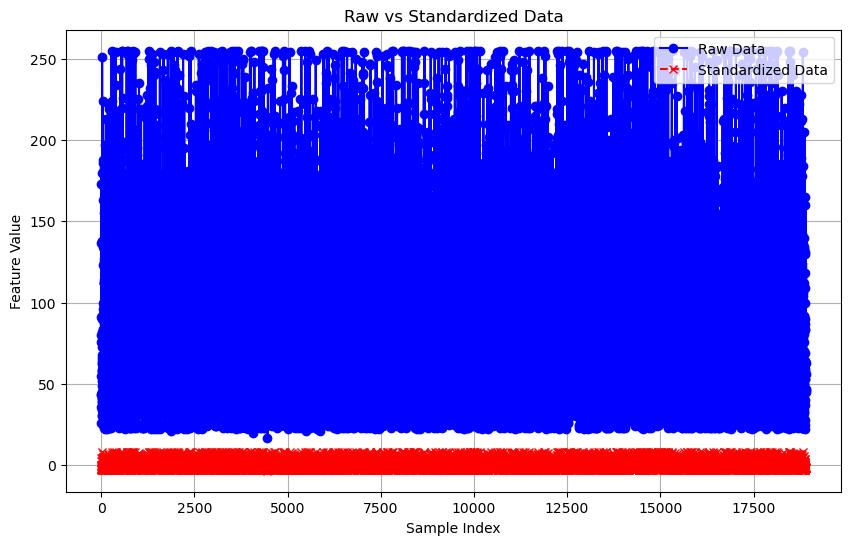

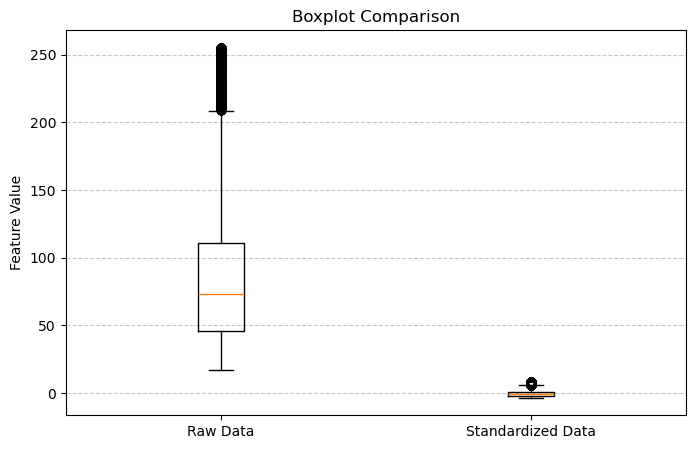

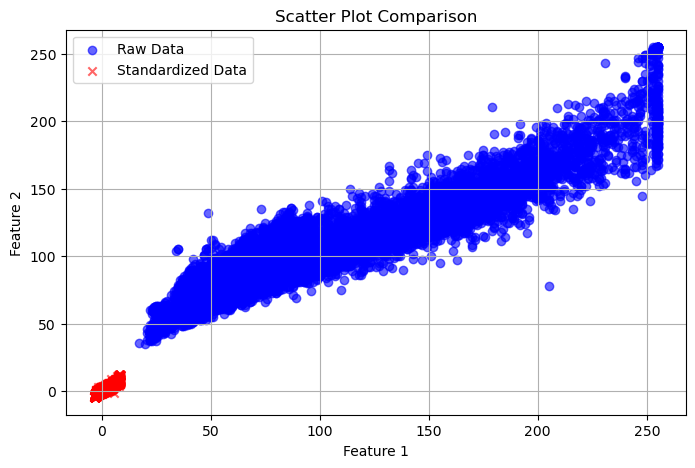

In [7]:
COC131.plot_comparison(
    x_train_feature_0,
    x_train_standardized_feature_0,
    label1="Raw Data",
    label2="Standardized Data",
    color1='blue',
    color2='red',
    title="Raw vs Standardized Data",
    xlabel="Sample Index",
    ylabel="Feature Value"
)

# Spread of data
COC131.plot_boxplot_comparison(
    x_train_feature_0,
    x_train_standardized_feature_0,
    label1="Raw Data",
    label2="Standardized Data",
    title="Boxplot Comparison",
    ylabel="Feature Value")

# Data viewed on a 2d embedding
COC131.plot_scatter_comparison(x_train,
    x_train_standardized,
    label1="Raw Data",
    label2="Standardized Data",
    title="Scatter Plot Comparison",
    xlabel="Feature 1",
    ylabel="Feature 2")

### Part 1: Investigate a single feature
For each of these, **Feature 0** was extrapolated and its behaviour was investigated and compared with against its standardized counterpart.

#### Plot 1 – Line Plot of Feature Values
- Shows that raw values have a much greater range accross the entire feature space, compared to standardized

#### Plot 2 – Scatter Plot of Features
- Compares the 2D Distribution of the first two features before and after standardization
- Although the shape remains the same, the range is significantly more compressed as more units are "bunched" together due to standardization
    - This validates the effects of standardization

#### Plot 3 - Boxplot
- Shows wide spread (a large interquartile range) and significant outliers, implying that the feature is highly skewed or has extreme values.
- The Standardized Data boxplot, on the other hand, is more compact and has fewer outliers, suggesting that the standardization has effectively handled the variance and the extreme values. It’s more tightly clustered around the median.

[2.5 2.5 2.5 ... 2.5 2.5 2.5]


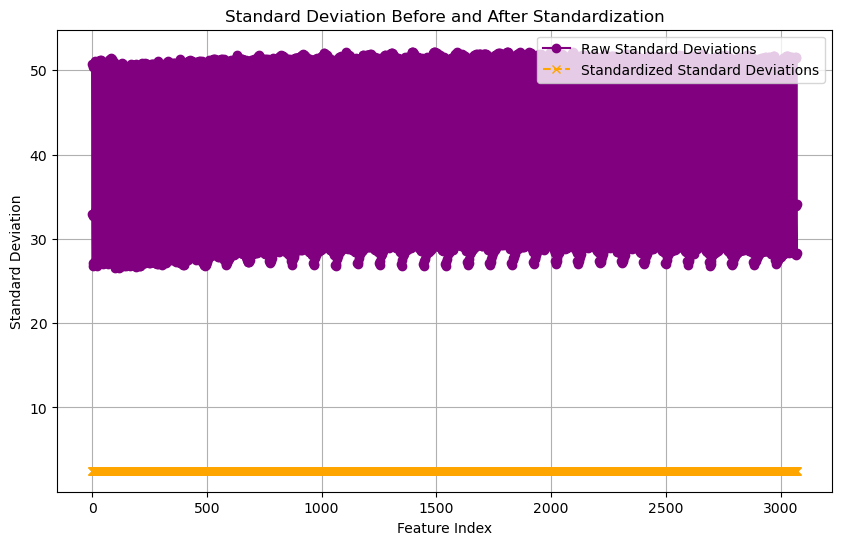

[ 1.74228650e-16  6.74066916e-16  1.36340087e-16 ... -9.50679864e-17
 -4.94642540e-16 -5.77571500e-16]


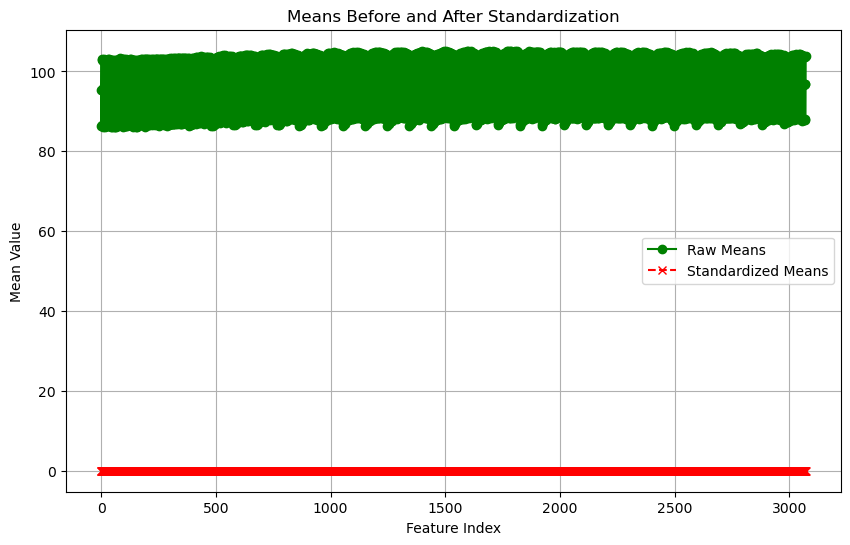

In [8]:
stds = np.std(x_train, axis=0)
stds_standardized = np.std(x_train_standardized, axis=0)
print(stds_standardized)
COC131.plot_comparison(
    stds,
    stds_standardized,
    label1="Raw Standard Deviations",
    label2="Standardized Standard Deviations",
    color1='purple',
    color2='orange',
    title="Standard Deviation Before and After Standardization",
    xlabel="Feature Index",
    ylabel="Standard Deviation",
)
means = np.mean(x_train, axis=0)
means_standardized = np.mean(x_train_standardized, axis=0)
print(means_standardized)
COC131.plot_comparison(
    means,
    means_standardized,
    label1="Raw Means",
    label2="Standardized Means",
    color1='green',
    color2='red',
    title="Means Before and After Standardization",
    xlabel="Feature Index",
    ylabel="Mean Value",
)

### Part 2: Investigating features as a whole
- Here, we use mean and standard deviation of the entire dataset to investigate the effects of standardization of every feature
- As defined from earlier, standardized values have a mean of 1, and a standard deviation of the unit applied
  - So in this case, every single feature has a mean of 1, and a standard deviation of 2.5, as shown in the two plots

#### Means
- Before standardization, each images pixel values averaged to a mean of between 105 and 85
- After, it was standardized to 0, or at least very close to it
- This is expected behaviour

#### Standard Deviation
- Before standardization, each images pixel values were between about 26 and 51
- After, it was standardized to 2.5, which is the unit standard deviation defined in q2
- This is also expected behaviour

## Q3 Finding the most optimal hyperparameters
- This function either takes hyperparaneters, or if not provided, will iterate through a combination of hyperperameters and give a result
- For the case when no hyperparameters are provided, its aim is to find the best model for this dataset and return its performance metrics over the full epochs
- A sequential, staged approach was adopted for this, where each "stage" investigates how changing one parameter, while keeping others fixed, affects the model, and thereby, finding out the best version of that hyperparameter and using it in the next stage
- This staged approach also takes into consideration commonly accepted heuristics for different hyperparameters:
  - For instance, it has a learning rate dictionary for both SGD and Adam, as both would typically require different learning rate scales, and testing the same learning rates across both would introduce redundancy, since solvers are optimized for different ranges
- Helper functions are also leveraged and reused accross the training and evaluation loops, to ensure clear seperation of concerns and maintainance update logic for hyperparameters

In [6]:
model, loss_curve, train_acc, test_acc = coc131.q3(test_size=0.3)

Stage 1: Testing hidden layer configurations with Adam
Testing hyperparam(s): {'hidden_layer_sizes': (16,)}
New best configuration: {'hidden_layer_sizes': (16,)}, Validation score: 0.5701265133995375
Testing hyperparam(s): {'hidden_layer_sizes': (32,)}
New best configuration: {'hidden_layer_sizes': (32,)}, Validation score: 0.5742075908039722
Testing hyperparam(s): {'hidden_layer_sizes': (32, 16)}
Testing hyperparam(s): {'hidden_layer_sizes': (64, 32)}
New best configuration: {'hidden_layer_sizes': (64, 32)}, Validation score: 0.5932526186913345
Testing hyperparam(s): {'hidden_layer_sizes': (128, 64)}
New best configuration: {'hidden_layer_sizes': (128, 64)}, Validation score: 0.610801251530404
Conclusion: After testing different hidden layer configurations, (128, 64) gave the best validation score
Stage 2: Testing activation functions with Adam and best hyperparameters: {'hidden_layer_sizes': (128, 64)}
Testing hyperparam(s): {'activation': 'relu'}
New best configuration: {'hidden_lay

### What was discovered 

This will document the discoveries made through running this function through every stage

#### Stage 1

- **Tested configurations**: `(16,)`, `(32,)`, `(32, 16)`, `(64, 32)`, `(128, 64)`
- **Best configuration**: `(128, 64)`
- **Observation**: Increasing the number and size of hidden layers improved performance, with the best results coming from the deepest network, likely due to being better at capturing more complex patterns in the dataset

#### **Stage 2: Activation Function**

- **Tested**: `'relu'`, `'tanh'`
- **Best**: `'relu'`
- **Observation**: ReLU outperformed Tanh
  - This is expected, as ReLU typically performs better for image classification problems

#### **Stage 3: Solver**
Two prebuilt configurations were tested against:
- **Adam Solver** with a learning rate of constant, since Adam rarely benefits from an adaptive learning rate due to its built in adaptiveness
- **SGD Solver** with the addition of momentum and an adaptive learning rate, providing SGD with the tools that are typically accompanied with SGD in most training loops
---
- **Tested**: `SGD` (with momentum and adaptive learning rate) vs. `Adam`
- **Best**: `SGD` with momentum `0.9` and learning rate strategy `'adaptive'`
- **Observation**: SGD performed better on this dataset

#### **Stage 4: Learning Rate Strategy**
Since Adam doesnt benefit from this as much, or at all in some cases, due to it inherently being an adaptive model, this was conditionally only tested on SGD, provided it won earlier, which it did

---
- **Tested**: `'constant'`, `'adaptive'`
- **Best**: `'adaptive'`
- **Observation**: The adaptive strategy led to better performance
  - Adaptive learning means the learning rate adjusts, so in this case it likely allowed for it to slow down when converging to a minima, reaching a higher accuracy score overall

#### **Stage 5: Learning Rate Initialization**
Since both SGD and Adam generally thrive off of different learning rate ranges: Adam typically requires performs better on smaller learning rates, whilst SGD typically performs better when having slightly higher starting learning rate, this was taken into account by having two seperate configurations for each

---
- **Tested**: `0.0005`, `0.001`, `0.005` (Since SGD won earlier)
- **Best**: `0.005`
- **Observation**: A learning rate of `0.005` gave the best result
  - This is likely due to it being a balance between fast convergance and generalization of patterns

#### **Stage 6: Batch Size**

- **Tested**: `32`, `64`, `128`
- **Best**: `128`
- **Observation**: Larger batch sizes resulted in better validation scores.


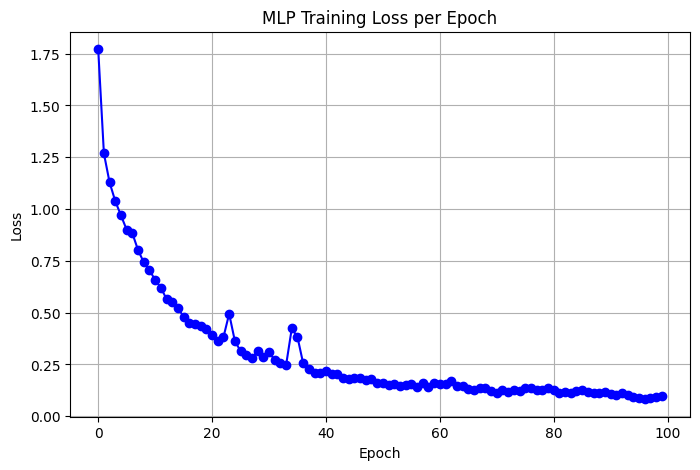

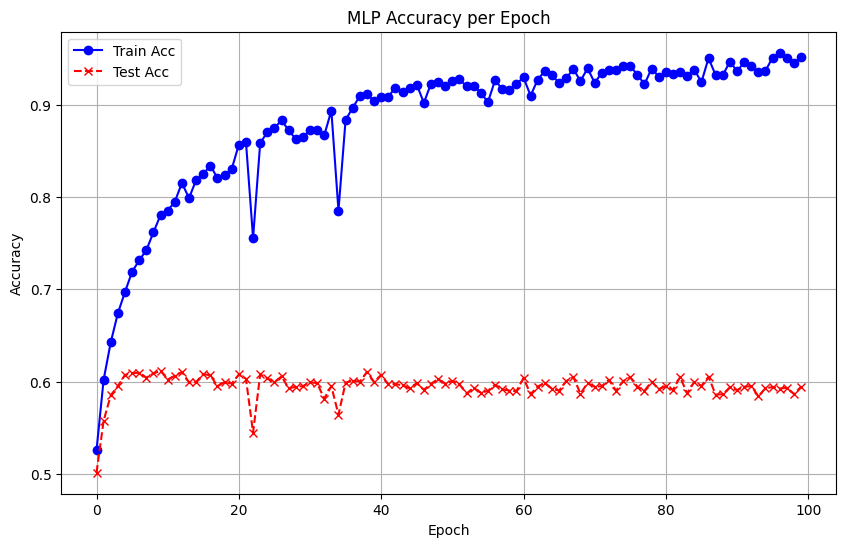

In [7]:
# Plot loss curve
COC131.plot_single(
    y=loss_curve,
    label="Loss",
    title="MLP Training Loss per Epoch",
    xlabel="Epoch",
    ylabel="Loss"
)

# Plot train vs. test accuracy
COC131.plot_comparison(
    y1=train_acc,
    y2=test_acc,
    label1="Train Acc",
    label2="Test Acc",
    title="MLP Accuracy per Epoch",
    xlabel="Epoch",
    ylabel="Accuracy"
)

 - The training results show the optimal hyperparams being trained at the end, illustrating its training and testing accuracy throughout the 100 epochs
 - From q3, we have been able to find the optimal hyperparameters, which can be used in the remaining questions to investigate other areas of training and distribution

## Q4: Effect of Alpha on MLPClassifier Performance and Parameters

- In this question, we analyze how the regularization parameter `alpha` affects both the performance and weights and biases of an `MLPClassifier`
- We use the optimal hyperparameter values from q3 in this section
- Our function captures many metrics, which will be visualized including:

  - Weight & bias norms, std, and mean values
  - Train & Test loss & accuracy
  - Overfitting gaps - derived from accuracy data
  - Raw weight values which are used for box plots

- Numpy is used accross the function to ensure efficient array manipulation when capturing weight and bias data

The results are visualized below using Line Graphs for summarized metrics, and boxplots for distributed metrics

In [5]:
metrics = coc131.q4()

Testing alpha value 1/13: alpha=0

Testing alpha value 2/13: alpha=0.001

Testing alpha value 3/13: alpha=0.005

Testing alpha value 4/13: alpha=0.01

Testing alpha value 5/13: alpha=0.05

Testing alpha value 6/13: alpha=0.1

Testing alpha value 7/13: alpha=0.5

Testing alpha value 8/13: alpha=1

Testing alpha value 9/13: alpha=2

Testing alpha value 10/13: alpha=5

Testing alpha value 11/13: alpha=10

Testing alpha value 12/13: alpha=50

Testing alpha value 13/13: alpha=100



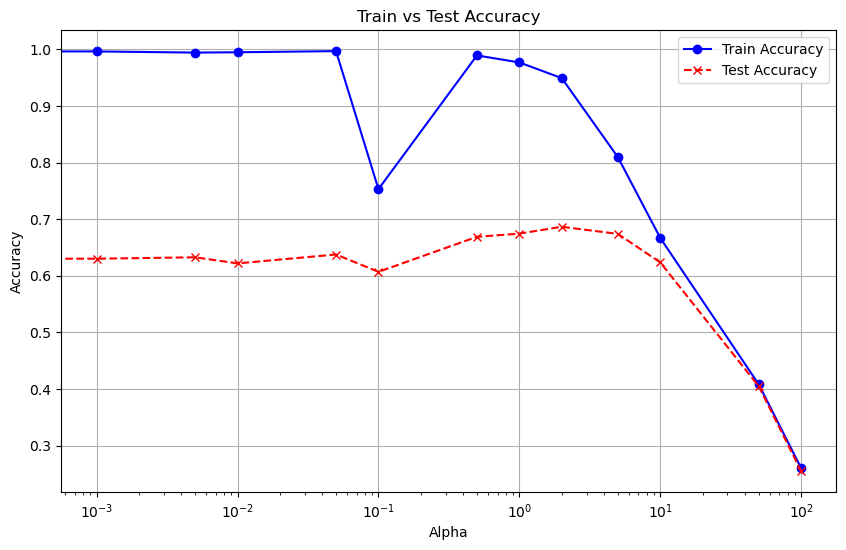

In [17]:
COC131.plot_comparison(
    y1=metrics['train_accs'],
    y2=metrics['test_accs'],
    x=metrics['alpha'],
    label1="Train Accuracy",
    label2="Test Accuracy",
    title="Train vs Test Accuracy",
    xlabel="Alpha",
    ylabel="Accuracy",
    xscale='log'
)

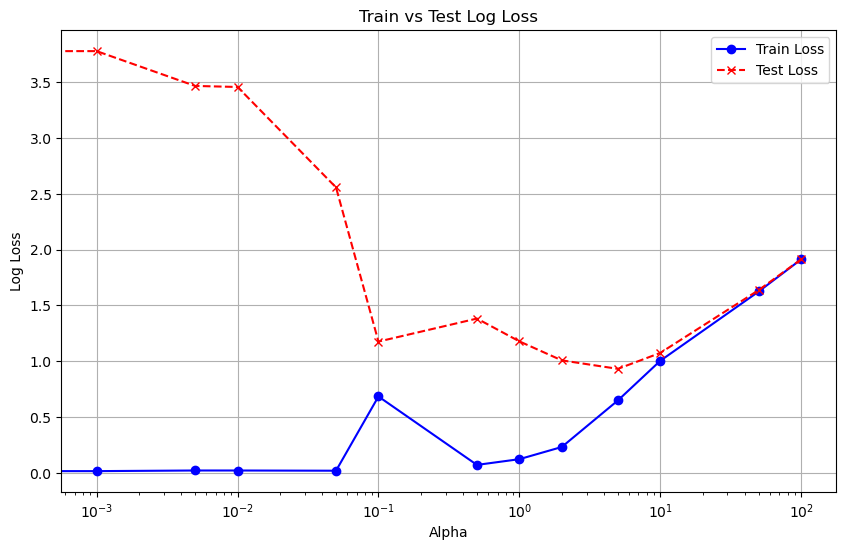

In [18]:
COC131.plot_comparison(
    y1=metrics['train_losses'],
    y2=metrics['test_losses'],
    x=metrics['alpha'],
    label1="Train Loss",
    label2="Test Loss",
    title="Train vs Test Log Loss",
    xlabel="Alpha",
    ylabel="Log Loss",
    xscale='log'
)

### Train vs Test loss
- **Very low** train loss for **very small alphas**, with a correspondingly **large test loss**
  - Shows signs in high amounts of **overfitting**
- As `alpha` slowly increases, the test loss **sharply decreases**, suggesting that regularization improved generalization
- The overfitting balances out at around 0.001 to 0.1, where they are close together, but the model is still likely able to accurately predict
  - It reaches a **good balance** for variance here
- For higher alphas in the ranges of 10+, significant signs of **underfitting** are seen as the train and test loss completely converge together

These results show the purpose of `alpha`: A complexity controller, where too little can lead to overfitting, and too much and lead to underfitting

### Accuracy
- This is essentially showing the exact same thing happening, but within the context of accuracy

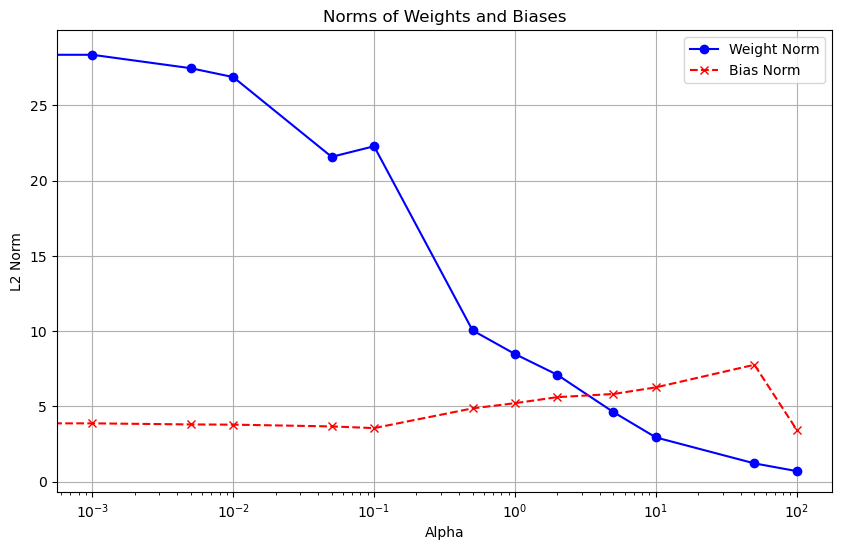

In [19]:
COC131.plot_comparison(
    y1=metrics['weight_norms'],
    y2=metrics['bias_norms'],
    x=metrics['alpha'],
    label1="Weight Norm",
    label2="Bias Norm",
    title="Norms of Weights and Biases",
    xlabel="Alpha",
    ylabel="L2 Norm",
    xscale='log'
)

### Norms of weights and biases
- Summarizes how the norms of weights and biases change as `alpha` increases
- **Weights (blue)**:
  - Stays fairly high and stable for low alphas
    - Lack of regularization here is causing there to be no restriction on the weights, causing some to be very large, increasing the overall magnitude
  - As `alpha` gets past 0.1, it has a **steep drop** throughout all other alphas, as a result of the increased weight penalization
  - This fully extends to the **very large** `alpha`'s, where its forced to keep the weights extremely small
- **Biases (red)**:
  - Stable and flat for smaller alphas, showing minimal change
  - Up until about `alpha` 0.1, where it starts slowly increasing
    - This happens because biases are not affected by L2 regularization, and thus, the lack of weight diversity causes the model to increase the bias in an attempt to classify the model better

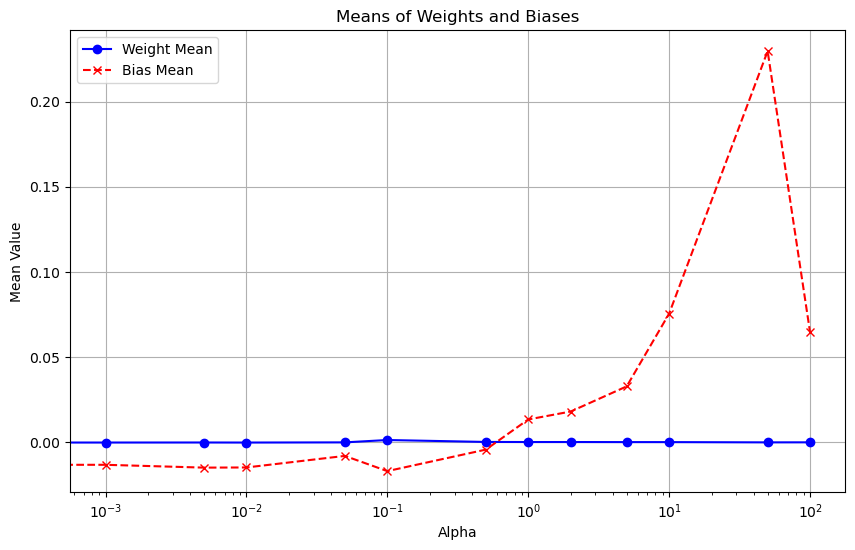

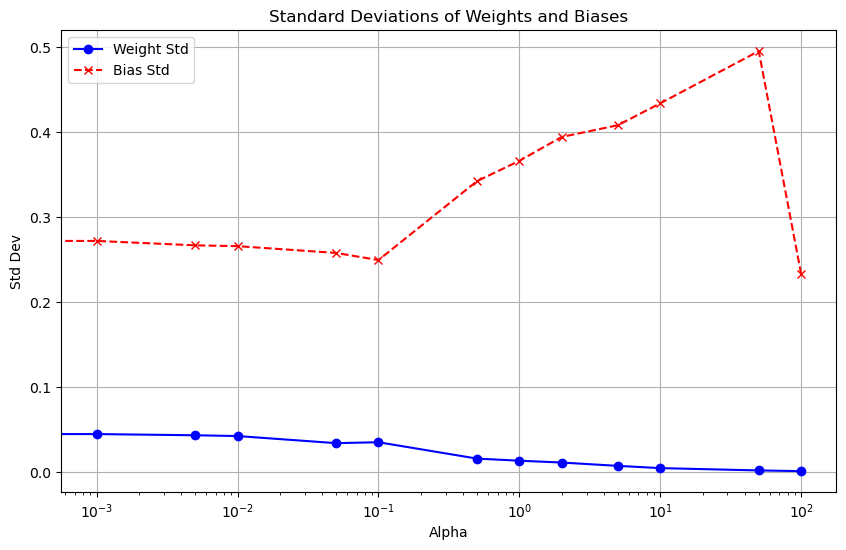

In [20]:
COC131.plot_comparison(
    y1=metrics['weight_means'],
    y2=metrics['bias_means'],
    x=metrics['alpha'],
    label1="Weight Mean",
    label2="Bias Mean",
    title="Means of Weights and Biases",
    xlabel="Alpha",
    ylabel="Mean Value",
    xscale='log'
)

COC131.plot_comparison(
    y1=metrics['weight_stds'],
    y2=metrics['bias_stds'],
    x=metrics['alpha'],
    label1="Weight Std",
    label2="Bias Std",
    title="Standard Deviations of Weights and Biases",
    xlabel="Alpha",
    ylabel="Std Dev",
    xscale='log'
)

### Means of weights and biases
Shows how average values of weights and biases change accross `alpha`
- **Weights (blue)**:
  - Mean stays very close to 0 accross all alpha values
    - In low alphas, this is due to negative weights distributing the mean to 0, as there is a natural balanace between positive and negative weights
    - In large alpha, this is due to weight magnitude suppression, keeping all weights very small
- **Biases (red)**:
  - Stays fairly stable until about `alpha = 1`, where it rises sharply
    - Biases are not penalized by regularization, so this makes sense
      - Due to the restricted nature of weights through regularization, the model will attempt to use biases more to fit data (as also explained in the cell above)
   
### Stds of weights and biases
Illustrates the "spread" of weight and biases as `alpha` increases
- **Weights (blue)**:
  - Steady decline as alpha increases
    - Due to a **reduced diversity** in weights, making them significantly less spread out
- **Biases (red)**:
  -  Keeps stable at low alphas, begins rising at `alpha = 1`
  - Drastic spike after about 1-10 onwards
    - As the model cannot rely on diverse weights

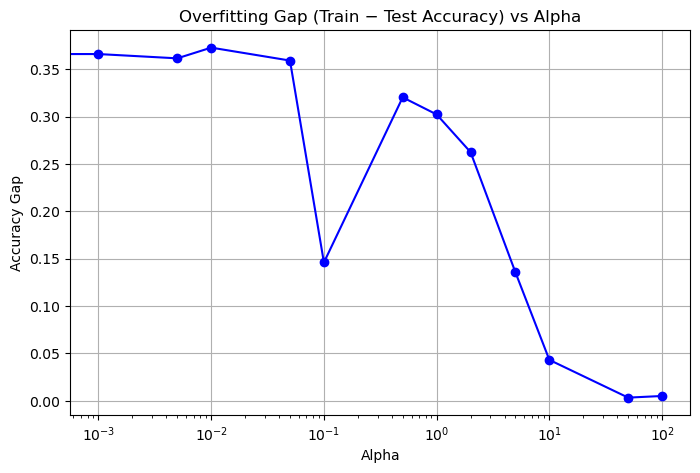

In [21]:
COC131.plot_single(
    y=metrics['acc_gaps'],
    x=metrics['alpha'],
    label="Overfitting Gap",
    title="Overfitting Gap (Train − Test Accuracy) vs Alpha",
    xlabel="Alpha",
    ylabel="Accuracy Gap",
    xscale='log'
)

### Overfitting gap
This graph displays the gap between the training and the testing metrics through `alpha`
- Largest overfitting occuring over the **very low** `alpha` values, where there is almost zero regularization, with the model fully running for the full number of iterations with minimal weight restriction
- At `alpha = 0.1` noticably, the gap **drops sharply**, indicating that even a small amount of regularization can help again overfitting
  - This decreases is only temporary as it then spikes back up
- As `alpha` continues increase, there is a sharp decline in overfitting, until it leads to underfitting, performing the same on both train and test set, but not very well, as observed in the accuracy graph

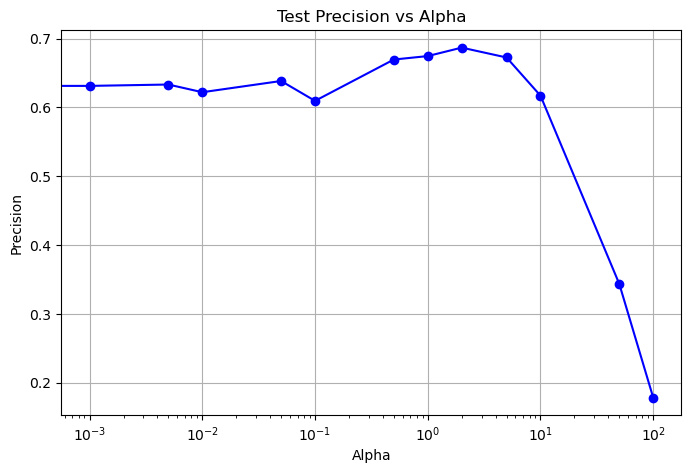

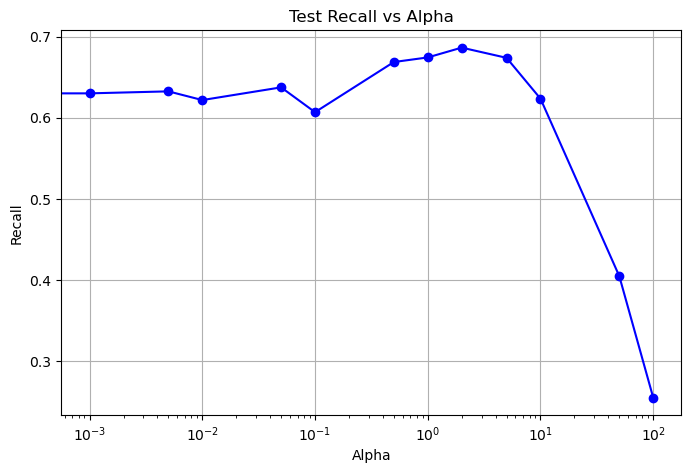

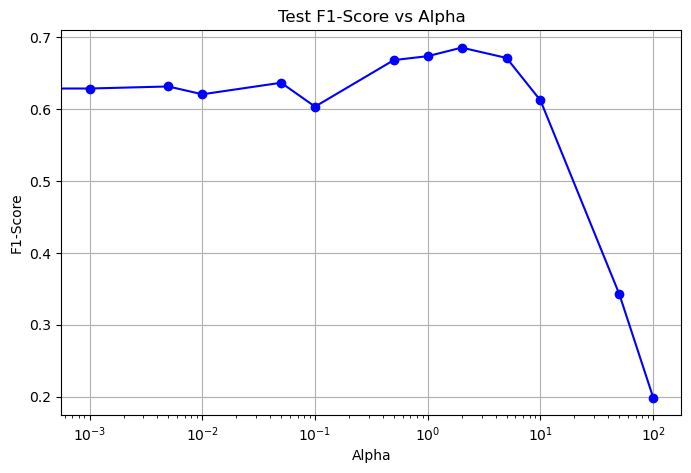

In [22]:
COC131.plot_single(
    y=metrics['test_precisions'],
    x=metrics['alpha'],
    label="Test Precision",
    title="Test Precision vs Alpha",
    xlabel="Alpha",
    ylabel="Precision",
    xscale='log'
)

COC131.plot_single(
    y=metrics['test_recalls'],
    x=metrics['alpha'],
    label="Test Recall",
    title="Test Recall vs Alpha",
    xlabel="Alpha",
    ylabel="Recall",
    xscale='log'
)

COC131.plot_single(
    y=metrics['test_f1s'],
    x=metrics['alpha'],
    label="Test F1-Score",
    title="Test F1-Score vs Alpha",
    xlabel="Alpha",
    ylabel="F1-Score",
    xscale='log'
)

### Precision, Recall and F1 Score
Precision, Recall, and F1 Score are all valuable metrics to measure what accuracy is unable to do, by taking into account True Positives, False Negatives etc.
- **Precision** is how many of the models positive predictions were actually correct
- **Recall** is how many of the actual positives the model correctly predicted as positive
- **F1 Score** is the balance between precision and recall
All these scores serve as a useful tool when investigating how well a model is able to generalize where accuracy can otherwise be misleading
---
- For small alphas, precision, recall and F-1 are **relatively stable**
- The peak scores for all of these metrics occurs at around `alpha = 1`, indicating that generalization is improved here, by...
  - Suggest a slight regularization is beneficial in preventing overfitting for this model
- However, after alpha extends from 0.1, all metrics drop suddently
  - Suggests that weights are getting heavily penalized, causing the weight ranges to also be much closer togehter (which we will see)
  - For large alphas, there is a clear sign of underfitting, as the model is unable to capture meaningful patterns through its restricted weight domain

C:\Users\tommy\AppData\Local\Temp\ipykernel_3328\2333401149.py:681: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels)


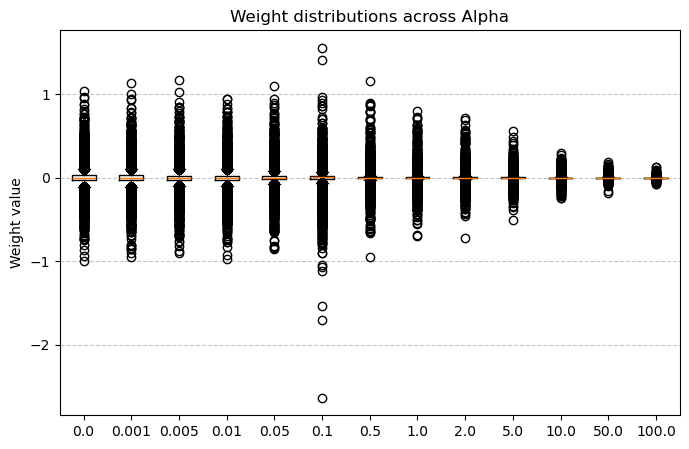

In [23]:
COC131.plot_boxplot(
    data=metrics['all_weights'],
    labels=metrics['alpha'],
    title="Weight distributions across Alpha",
    ylabel="Weight value"
)

C:\Users\tommy\AppData\Local\Temp\ipykernel_3328\2333401149.py:681: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels)


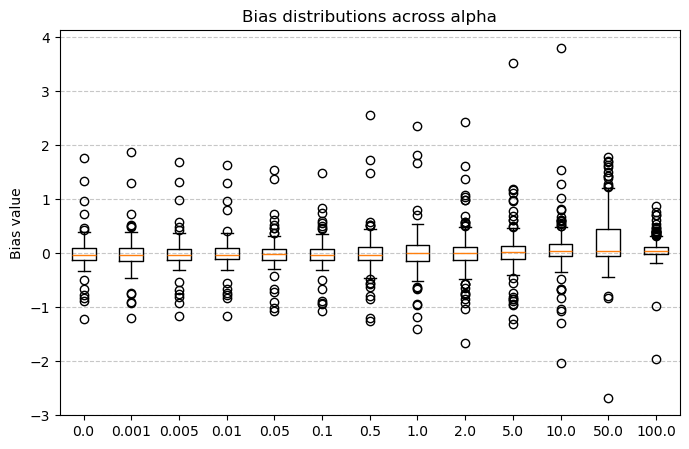

In [24]:
COC131.plot_boxplot(
    data=metrics['all_biases'],
    labels=metrics['alpha'],
    title="Bias distributions across alpha",
    ylabel="Bias value"
)

### Boxplots
- Showcase the spread of the weights and biases as alpha changes
- As observed, as `alpha` increases to the higher ranges of 1+, the spread of the weights gets significantly more **compressed**
- This is due to the **amplified alpha**, significantly **restricting the range** of the models weights, creating a more **simpler** model, that reaches convergance fast, but also underfits
- Correspondingly, as alpha increases, the biases get even more spread out
  - This makes sense since as discussed before, biases are not effected by L2 regularization, and thus, having a restricted pool of weights means the model will attempt to have more varied biases in order to try and fit the data

## Q5 - Investigate the effects of Cross-Validation between using KFold and StratifiedKFold on an MLP using Hypothesis Testing

- This question aims to solve whether using `StratifiedKFold` (preserving class distribution) versus `KFold` impacts the accuracy of MLPClassifier to a significant degree
  - Important in models that have inbalanced datasets as a way of investigating whether the inbalan

- This is evaluated using hypothesis testing

- In q5, we also standardize the X values

- The paired t-test was captured here to reach a justified conclusion of whether the change of KFold impacted the performance of the model

In [31]:
strat_scores, unstrat_scores, p_value, conclusion = coc131.q5()

In [32]:
print(f"Mean accuracy with stratified CV: {strat_scores:.4f}")
print(f"Mean accuracy with standard CV: {unstrat_scores:.4f}")
print(f"P-value (paired t-test): {p_value:.6f}")
print(f"Conclusion: {conclusion}")

Mean accuracy with stratified CV: 0.6415
Mean accuracy with standard CV: 0.6385
P-value (paired t-test): 0.473199
Conclusion: Splitting method had no effect


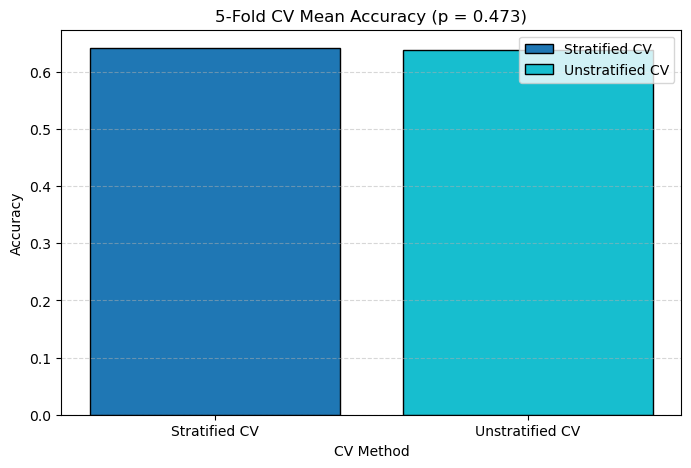

In [33]:
methods = ["Stratified CV", "Unstratified CV"]
scores  = [strat_scores, unstrat_scores]

COC131.plot_bar(
    categories=methods,
    values=scores,
    title=f"5-Fold CV Mean Accuracy (p = {p_value:.3f})",
    xlabel="CV Method",
    ylabel="Accuracy"
)

### Results
- Although Unstratified CV game a slightly higher mean accuracy, it was not enough to determine the conclusion of effecting the results
  - As the significance level concluded with not enough difference

## Q6 - Local Linear Embedding to produce a 2D view of all samples

- This question uses Local Linear Embedding (LLE) to plot all images onto a 2D plane
- It is important that these images are standardized first, which is achieved in the function

In [ ]:
result = coc131.q6()

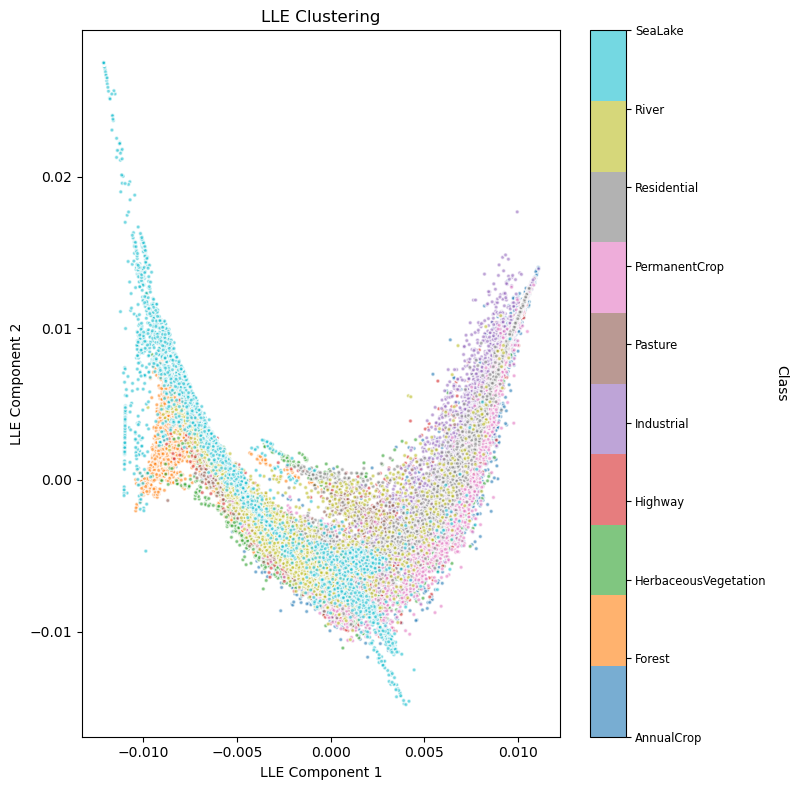

In [ ]:
COC131.plot_embedding(
    x=result['x_lle'],
    y=result['y'],
    class_names=coc131.class_names,
    title="LLE Clustering",
    xlabel="LLE Component 1",
    ylabel="LLE Component 2"
)

### The Embedding Plot
- Shows the 2D representation of the database using LLE
- Each point represents sample in dataset
#### What it shows
- **SeaLake** is the most noticible due to them being the most spread out within the embedding
  - This suggests significant **internal variability** — The samples differ quite a bit from each other in the actual data
- **Forest** seems to occupy a more compact region in the space
  - This suggests that the forest samples are more **internally consistent** - share simillar features to one another that make them hard to distinguish
- Some overlapping is occuring between particular samples, such as Residntial, Pasture and Highway
  - This indicates that that these samples offer **less distinguishable** features